In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
# 1. Import the dataset using Pandas
df = pd.read_csv('IMDB Dataset.csv')

In [5]:
# 2. Print the first three and last three rows of the dataset
print("--- First 3 Rows ---")
print(df.head(3))

print("\n--- Last 3 Rows ---")
print(df.tail(3))

--- First 3 Rows ---
                                         Poster_Link  \
0  https://m.media-amazon.com/images/M/MV5BMDFkYT...   
1  https://m.media-amazon.com/images/M/MV5BM2MyNj...   
2  https://m.media-amazon.com/images/M/MV5BMTMxNT...   

               Series_Title  Released_Year Certificate  Runtime  \
0  The Shawshank Redemption           1994           A      142   
1             The Godfather           1972           A      175   
2           The Dark Knight           2008          UA      152   

                  Genre  IMDB_Rating  \
0                 Drama          9.3   
1          Crime, Drama          9.2   
2  Action, Crime, Drama          9.0   

                                            Overview              Director  \
0  Two imprisoned men bond over a number of years...        Frank Darabont   
1  An organized crime dynasty's aging patriarch t...  Francis Ford Coppola   
2  When the menace known as the Joker wreaks havo...     Christopher Nolan   

           

In [6]:
# 3. Check the detailed information of the dataset
print("\n--- Dataset Info ---")
df.info()


--- Dataset Info ---
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Poster_Link    200 non-null    str    
 1   Series_Title   200 non-null    str    
 2   Released_Year  200 non-null    int64  
 3   Certificate    200 non-null    str    
 4   Runtime        200 non-null    int64  
 5   Genre          200 non-null    str    
 6   IMDB_Rating    200 non-null    float64
 7   Overview       200 non-null    str    
 8   Director       200 non-null    str    
 9   Star1          200 non-null    str    
 10  Star2          200 non-null    str    
 11  Star3          200 non-null    str    
 12  Star4          200 non-null    str    
 13  No_of_Votes    200 non-null    int64  
dtypes: float64(1), int64(3), str(10)
memory usage: 22.0 KB


In [7]:
# 4. Check if any null values are present or not in the dataset
print("\n--- Null Values Count ---")
print(df.isnull().sum())
print("Any null values present?:", df.isnull().values.any())


--- Null Values Count ---
Poster_Link      0
Series_Title     0
Released_Year    0
Certificate      0
Runtime          0
Genre            0
IMDB_Rating      0
Overview         0
Director         0
Star1            0
Star2            0
Star3            0
Star4            0
No_of_Votes      0
dtype: int64
Any null values present?: False


In [8]:
# 5. Create a subset of the original dataset with data of row number between 41 to 75
# Note: Using iloc[40:75] selects rows 41 through 75 (1-based row numbering)
subset_df = df.iloc[40:75]
print("\n--- Subset (Rows 41 to 75) ---")
print(subset_df)


--- Subset (Rows 41 to 75) ---
                                          Poster_Link  \
40  https://m.media-amazon.com/images/M/MV5BZjA0MT...   
41  https://m.media-amazon.com/images/M/MV5BYTViNj...   
42  https://m.media-amazon.com/images/M/MV5BODllNW...   
43  https://m.media-amazon.com/images/M/MV5BYTYxNG...   
44  https://m.media-amazon.com/images/M/MV5BMGU2Nz...   
45  https://m.media-amazon.com/images/M/MV5BM2FhYj...   
46  https://m.media-amazon.com/images/M/MV5BZmY2Nj...   
47  https://m.media-amazon.com/images/M/MV5BZmU0M2...   
48  https://m.media-amazon.com/images/M/MV5BZGI5Mj...   
49  https://m.media-amazon.com/images/M/MV5BNTQwND...   
50  https://m.media-amazon.com/images/M/MV5BY2IzZG...   
51  https://m.media-amazon.com/images/M/MV5BYjJiZj...   
52  https://m.media-amazon.com/images/M/MV5BY2I4Mm...   
53  https://m.media-amazon.com/images/M/MV5BMmExNz...   
54  https://m.media-amazon.com/images/M/MV5BNWJhMD...   
55  https://m.media-amazon.com/images/M/MV5BY2FiMT...   

In [9]:
# 6. Check details of the movie that has the highest number of votes
# Adjust 'No_of_Votes' if your column is named 'Votes' or 'Vote_Count'
votes_col = 'No_of_Votes' if 'No_of_Votes' in df.columns else [c for c in df.columns if 'vote' in c.lower()][0]
highest_voted_movie = df[df[votes_col] == df[votes_col].max()]
print("\n--- Movie with Highest Number of Votes ---")
print(highest_voted_movie)

# Ensure Runtime is numeric (in case values are formatted like '142 min')
if df['Runtime'].dtype == 'object':
    df['Runtime'] = df['Runtime'].str.replace(' min', '', regex=False).astype(float)


--- Movie with Highest Number of Votes ---
                                         Poster_Link  \
0  https://m.media-amazon.com/images/M/MV5BMDFkYT...   

               Series_Title  Released_Year Certificate  Runtime  Genre  \
0  The Shawshank Redemption           1994           A      142  Drama   

   IMDB_Rating                                           Overview  \
0          9.3  Two imprisoned men bond over a number of years...   

         Director        Star1           Star2       Star3           Star4  \
0  Frank Darabont  Tim Robbins  Morgan Freeman  Bob Gunton  William Sadler   

   No_of_Votes  
0      2343110  


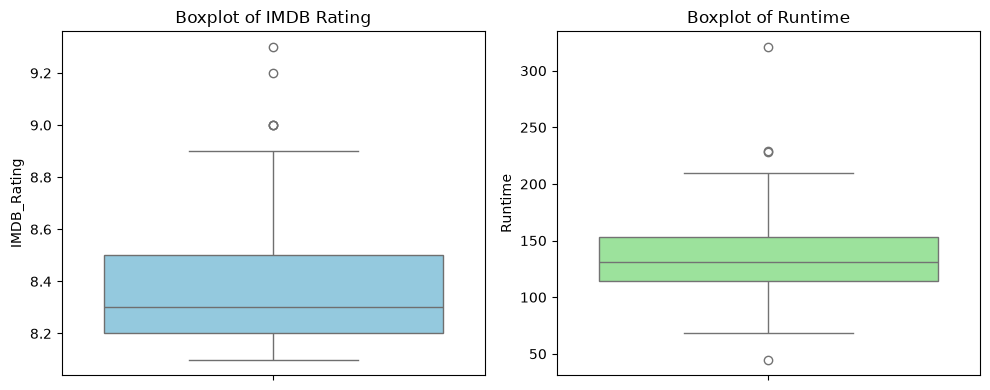

In [10]:
# 7. Create boxplot for features - IMDB_Rating and Runtime
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
sns.boxplot(y=df['IMDB_Rating'], color='skyblue')
plt.title('Boxplot of IMDB Rating')

plt.subplot(1, 2, 2)
sns.boxplot(y=df['Runtime'], color='lightgreen')
plt.title('Boxplot of Runtime')

plt.tight_layout()
plt.show()

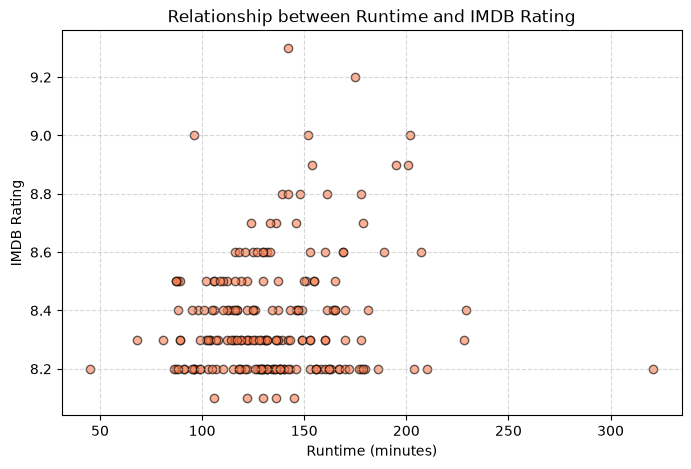

In [11]:
# 8. Check the relationship between features IMDB_Rating and Runtime using Matplotlib
plt.figure(figsize=(8, 5))
plt.scatter(df['Runtime'], df['IMDB_Rating'], alpha=0.6, color='coral', edgecolors='k')
plt.title('Relationship between Runtime and IMDB Rating')
plt.xlabel('Runtime (minutes)')
plt.ylabel('IMDB Rating')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

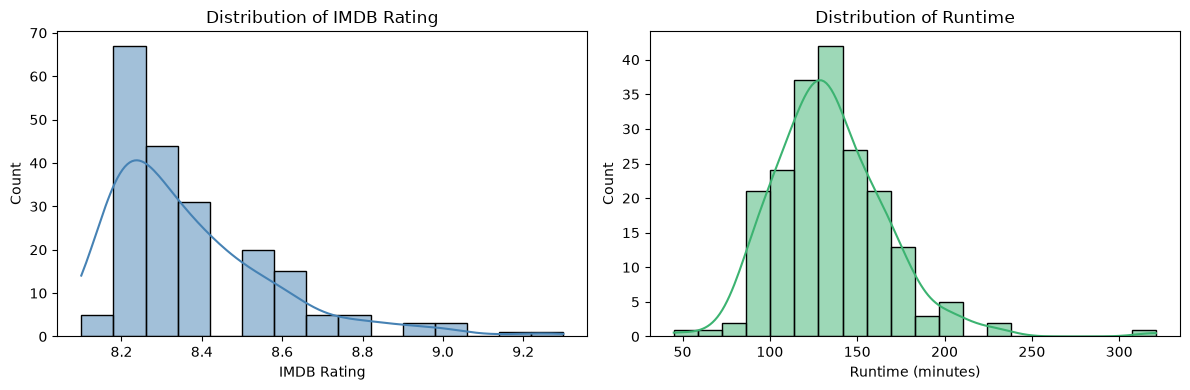

In [12]:
# 9. Check the distribution of features IMDB_Rating and Runtime
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sns.histplot(df['IMDB_Rating'], kde=True, color='steelblue', bins=15)
plt.title('Distribution of IMDB Rating')
plt.xlabel('IMDB Rating')

plt.subplot(1, 2, 2)
sns.histplot(df['Runtime'], kde=True, color='mediumseagreen', bins=20)
plt.title('Distribution of Runtime')
plt.xlabel('Runtime (minutes)')

plt.tight_layout()
plt.show()

C:\Users\imran\AppData\Local\Temp\ipykernel_101332\554297913.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=rating_col, order=df[rating_col].value_counts().index, palette='viridis')


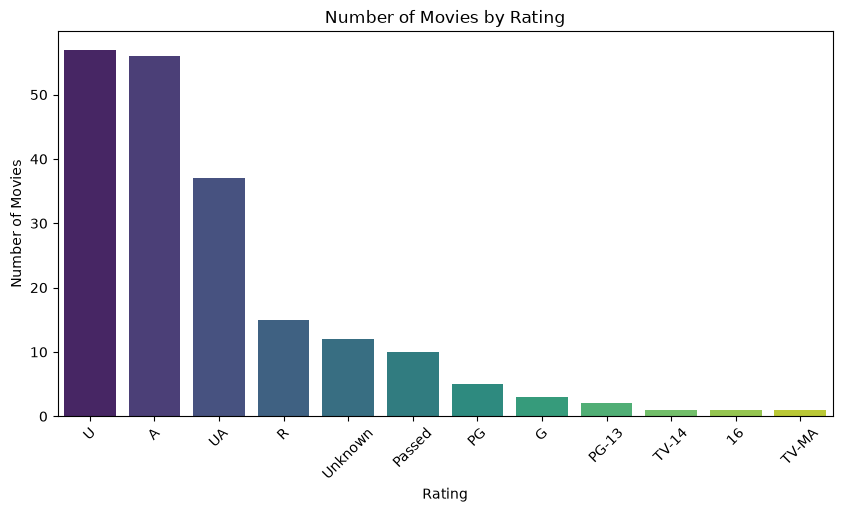

In [13]:
# 10. Create a count plot of feature Rating to display no. of movies with a particular rating
# Adjust 'Rating' if your dataset calls the certificate/content-rating column 'Certificate'
rating_col = 'Rating' if 'Rating' in df.columns else 'Certificate'

plt.figure(figsize=(10, 5))
sns.countplot(data=df, x=rating_col, order=df[rating_col].value_counts().index, palette='viridis')
plt.title('Number of Movies by Rating')
plt.xlabel('Rating')
plt.ylabel('Number of Movies')
plt.xticks(rotation=45)
plt.show()